In [1]:
import matplotlib.pyplot as plt
import platform
# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
"Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

In [2]:
import pandas as pd

df = pd.read_csv("sales_data.csv")
df.shape

(1030, 14)

In [3]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


In [4]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


In [5]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]

df.to_csv("sales_clean.csv", index=False)

print(df["date_error"].sum(), "건,", df.shape)

147 건, (1004, 15)


### Q1 배송 기간 (도착일 − 배송일) 은 보통 며칠인가

사용한 줄 : 852
평균 : 22.1  중앙값 : 2.0


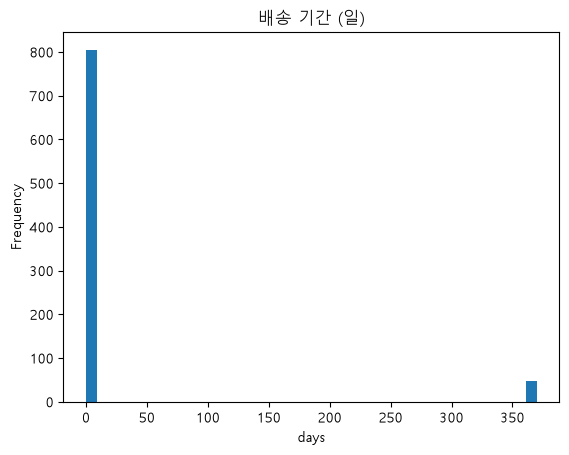

In [6]:
for col in ["shipping_date", "delivery_date"]:
    df[col] = pd.to_datetime(df[col])

ok = df[~df["date_error"]]
days = (ok["delivery_date"] - ok["shipping_date"]).dt.days
days = days.dropna()

print("사용한 줄 :", len(days))
print("평균 :", round(days.mean(), 1), " 중앙값 :", days.median())

days.plot.hist(bins=40, title="배송 기간 (일)")
plt.xlabel("days")
plt.show()

In [7]:
far = days[days > 300]
print("300일 초과 :", len(far), "건")
print(far.describe())

cols = ["order_date", "shipping_date", "delivery_date", "status"]
ok.loc[far.index, cols].head(10)

300일 초과 : 47 건
count     47.000000
mean     366.638298
std        1.798859
min      364.000000
25%      365.000000
50%      367.000000
75%      368.000000
max      370.000000
dtype: float64


,order_date,shipping_date,delivery_date,status
11,2023-01-12,2023-01-15,2024-01-15,배송완료
20,2023-01-21,2023-01-23,2024-01-27,배송완료
29,2023-01-30,2023-02-03,2024-02-03,배송완료
41,2023-02-11,2023-02-14,2024-02-17,배송완료
68,2023-03-10,2023-03-14,2024-03-12,배송완료
99,2023-04-10,2023-04-11,2024-04-12,배송완료
110,2023-04-21,2023-04-25,2024-04-24,배송완료
131,2023-05-12,2023-05-13,2024-05-16,배송완료
165,2023-06-15,2023-06-16,2024-06-18,배송완료
192,2023-07-12,2023-07-13,2024-07-14,배송중


1년 뺀 값 범위 : -1.0 ~ 5.0  정상 최대 : 5.0
처리 후 평균 : 1.9  중앙값 : 2.0


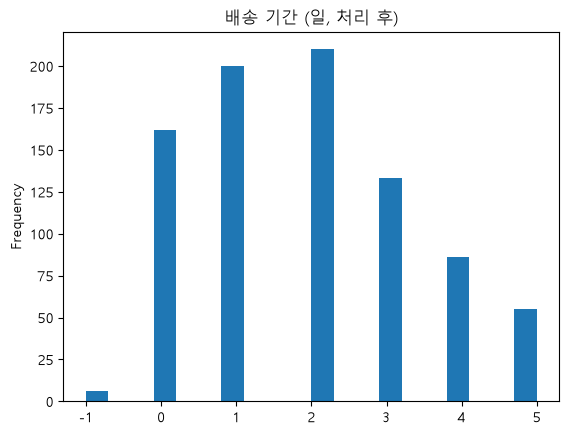

In [8]:
normal_max = days[days <= 300].max()
print("1년 뺀 값 범위 :", (far - 365).min(), "~", (far - 365).max(), " 정상 최대 :", normal_max)

fixed = days.copy()
fixed[days > 300] = days[days > 300] - 365
print("처리 후 평균 :", round(fixed.mean(), 1), " 중앙값 :", fixed.median())

fixed.plot.hist(bins=20, title="배송 기간 (일, 처리 후)")
plt.show()

1년(365일)을 뺀 뒤 일수 : -1.0 ~ 5.0
고쳐도 역전(음수) : 6 건
사용한 줄 : 846
처리 후 평균 : 1.9  중앙값 : 2.0


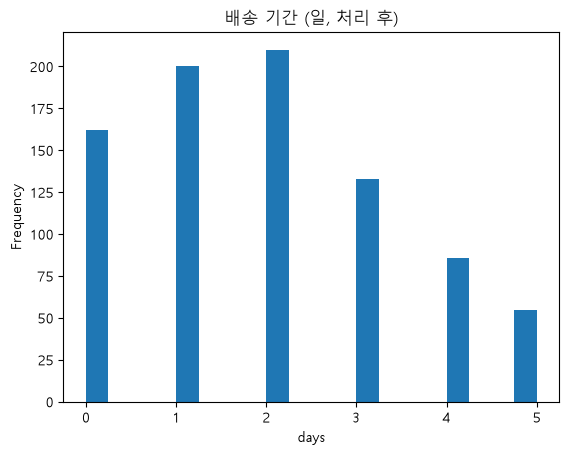

In [9]:
fixed_far = far - 365
print("1년(365일)을 뺀 뒤 일수 :", fixed_far.min(), "~", fixed_far.max())
print("고쳐도 역전(음수) :", (fixed_far < 0).sum(), "건")

fixed = days.copy()
fixed[far.index] = fixed_far
fixed = fixed[fixed >= 0]

print("사용한 줄 :", len(fixed))
print("처리 후 평균 :", round(fixed.mean(), 1), " 중앙값 :", fixed.median())

fixed.plot.hist(bins=20, title="배송 기간 (일, 처리 후)")
plt.xlabel("days")
plt.show()

### Q1 답
배송 기간은 보통 1.9일이다 (처리 후 846줄, 평균 1.9일 · 중앙값 2일).

처리 전 평균(22.1일)이 중앙값(2.0일)보다 컸던 것은 300일 초과 47건 때문이다. 이 줄들은 도착일 연도가 1년 뒤로 적힌 것으로 보여 365일을 빼서 복원했고(고친 뒤 0~5일), 고쳐도 도착일이 배송일보다 앞서는 6건은 제외했다.

### Q2 만족도가 낮을수록 반품이 많은가?

만족도 결측(제외) : 30 줄
전체 반품 비율 : 8.6 %
satisfaction
1.0     7.6
2.0    12.0
3.0     7.8
4.0     8.7
5.0     6.9
Name: status, dtype: float64


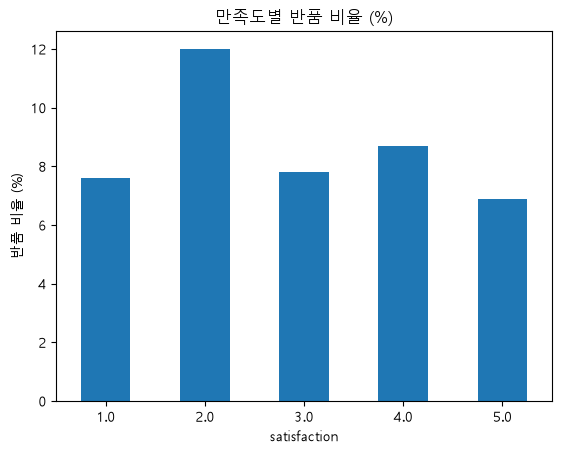

In [10]:
is_return = df["status"] == "반품"
rate = (is_return.groupby(df["satisfaction"]).mean() * 100).round(1)

print("만족도 결측(제외) :", df["satisfaction"].isnull().sum(), "줄")
print("전체 반품 비율 :", round(is_return.mean() * 100, 1), "%")
print(rate)

rate.plot.bar(title="만족도별 반품 비율 (%)", rot=0)
plt.xlabel("satisfaction")
plt.ylabel("반품 비율 (%)")
plt.show()

### Q2 답
아니다. 만족도 1~5의 반품 비율은 7.6% · 12.0% · 7.8% · 8.7% · 6.9%로, 만족도가 낮을수록 반품이 많아지는 경향은 보이지 않는다.

만족도 4(8.7%)의 반품 비율이 만족도 1(7.6%)의 반품 비율보다 1.1%p 오히려 높으며, 만족도 결측 30줄은 제외하고 계산했다.

### Q3 카테고리 매출 1위의 이유는 건수 · 단가 · 수량 중 무엇인가?

In [11]:
summary = df.groupby("category").agg(
    건수=("total_sales", "count"),
    매출합_억=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean"),
)
summary["매출합_억"] = summary["매출합_억"] / 1e8
summary = summary.sort_values("매출합_억", ascending=False).round(1)
summary

,건수,매출합_억,평균단가,평균수량
category,,,,
가구,213,28.4,257322.9,51.0
식품,210,25.1,255232.9,47.3
전자제품,207,24.7,249651.6,48.0
도서,204,24.5,238500.6,49.5
의류,170,21.8,249447.2,51.6


### Q3 답
매출 1위는 가구(28.4억 원)이며, 한 칸이 두드러지기보다 건수(213건)와 평균 단가(257,323원)가 함께 조금씩 가장 높은 것이 이유다.

다만 2위 식품(210건, 255,233원)과의 차이는 작고, 평균 수량(51.0개)은 의류(51.6개)보다 낮아 수량은 이유가 아니다.